In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker


# ..\data\05001 (Comunidades) Hechos conocidos de infracciones penales relacionadas con cibercriminalidad por grupo penal.csv
# ..\data\05005 (Comunidades) Hechos esclarecidos de infracciones penales relacionadas con cibercriminalidad por grupo penal.csv

# 1. Cargar Hechos Conocidos (05001) y Hechos Esclarecidos (05005)
ruta_conocidos = "../data/05001 (Comunidades) Hechos conocidos de infracciones penales relacionadas con cibercriminalidad por grupo penal.csv"
ruta_esclarecidos = "../data/05005 (Comunidades) Hechos esclarecidos de infracciones penales relacionadas con cibercriminalidad por grupo penal.csv"

df_con = pd.read_csv(ruta_conocidos, sep=";", thousands=".")
df_esc = pd.read_csv(ruta_esclarecidos, sep=";", thousands=".")



In [2]:
df_con["Grupo penal"].unique()

<StringArray>
[          'ACCESO  E INTERCEPTACIÓN ILÍCITA',
                      'AMENAZAS Y COACCIONES',
                            'CONTRA EL HONOR',
 'CONTRA LA PROPIEDAD INDUSTRIAL/INTELECTUAL',
                           'DELITOS SEXUALES',
                  'FALSIFICACIÓN INFORMÁTICA',
                         'FRAUDE INFORMÁTICO',
 'INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA',
                          'TOTAL grupo penal']
Length: 9, dtype: str

In [15]:
# Limpiar filas de ("TOTAL grupo penal") suma total de grupo penal 
df_cononocidos = df_con[df_con["Grupo penal"] != "TOTAL grupo penal"].copy()
df_esclarecidos = df_esc[df_esc["Grupo penal"] != "TOTAL grupo penal"].copy()

In [16]:
# Renombramos la columna "Total" en cada dataframe antes de cruzarlos
df_cononocidos.rename(columns={"Total": "Hechos_Conocidos"}, inplace=True)
df_esclarecidos.rename(columns={"Total": "Hechos_Esclarecidos"}, inplace=True)

In [19]:
#Cruzar ambas tablas por territorio, año y grupo penal

df_dataset4 = pd.merge(df_cononocidos, df_esclarecidos, on=["Comunidades autónomas", "periodo", "Grupo penal"], how="inner" )

df_dataset4

,Comunidades autónomas,Grupo penal,periodo,Hechos_Conocidos,Hechos_Esclarecidos
0,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2025,13753,1768
1,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2024,9773,1433
2,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2023,7367,1306
3,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2022,5578,1012
4,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2021,5342,1106
...,...,...,...,...,...
2635,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2015,0,0
2636,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2014,0,0
2637,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2013,0,0
2638,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2012,0,0


In [20]:
# Calculamos la tasa de esclarecimiento (%)
df_dataset4["Tasa_Esclarecimiento_%"] = ( (df_dataset4["Hechos_Esclarecidos"] / df_dataset4["Hechos_Conocidos"]) * 100 ).round()

df_dataset4

,Comunidades autónomas,Grupo penal,periodo,Hechos_Conocidos,Hechos_Esclarecidos,Tasa_Esclarecimiento_%
0,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2025,13753,1768,13.0
1,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2024,9773,1433,15.0
2,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2023,7367,1306,18.0
3,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2022,5578,1012,18.0
4,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2021,5342,1106,21.0
...,...,...,...,...,...,...
2635,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2015,0,0,NaN
2636,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2014,0,0,NaN
2637,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2013,0,0,NaN
2638,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2012,0,0,NaN


In [26]:
# Guardar el Dataset 4 
df_dataset4.sort_values(by=["periodo", "Comunidades autónomas", "Grupo penal", "Tasa_Esclarecimiento_%"], ascending=[False, True, True, False]).to_csv("../data/dataset4_hechos_esclarecidos.csv", index=False, sep=";" )

In [21]:
df_dataset4

,Comunidades autónomas,Grupo penal,periodo,Hechos_Conocidos,Hechos_Esclarecidos,Tasa_Esclarecimiento_%
0,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2025,13753,1768,13.0
1,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2024,9773,1433,15.0
2,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2023,7367,1306,18.0
3,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2022,5578,1012,18.0
4,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2021,5342,1106,21.0
...,...,...,...,...,...,...
2635,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2015,0,0,NaN
2636,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2014,0,0,NaN
2637,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2013,0,0,NaN
2638,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2012,0,0,NaN


In [22]:
# Evolución nacional por año DE LA TASA DE ESCLARECIMIENTO
nacional_esc = df_dataset4[df_dataset4["Comunidades autónomas"] == "TOTAL NACIONAL"].groupby("periodo")[ ["Hechos_Conocidos", "Hechos_Esclarecidos"]].sum().sort_index()

nacional_esc["Tasa_Esclarecimiento_%"] = ( nacional_esc["Hechos_Esclarecidos"] / nacional_esc["Hechos_Conocidos"] * 100 ).round()


nacional_esc.sort_values(by="periodo", ascending=False)




,Hechos_Conocidos,Hechos_Esclarecidos,Tasa_Esclarecimiento_%
periodo,,,
2025,488426,71340,15.0
2024,464801,64068,14.0
2023,472260,60225,13.0
2022,374737,51642,14.0
2021,305477,46141,15.0
2020,287963,38046,13.0
2019,218302,30841,14.0
2018,160729,27373,17.0
2017,117399,24348,21.0


In [23]:


# Tasa por Grupo Penal (Acumulado Nacional)
grupo_esc = df_dataset4[df_dataset4["Comunidades autónomas"] == "TOTAL NACIONAL"].groupby("Grupo penal")[ ["Hechos_Conocidos", "Hechos_Esclarecidos"] ].sum()
grupo_esc["Tasa_Esclarecimiento_%"] = ( grupo_esc["Hechos_Esclarecidos"] / grupo_esc["Hechos_Conocidos"] * 100 ).round()


grupo_esc.sort_values(by="Tasa_Esclarecimiento_%", ascending=False)




,Hechos_Conocidos,Hechos_Esclarecidos,Tasa_Esclarecimiento_%
Grupo penal,,,
CONTRA LA PROPIEDAD INDUSTRIAL/INTELECTUAL,2437,1543,63.0
DELITOS SEXUALES,21064,13355,63.0
CONTRA EL HONOR,23831,13528,57.0
AMENAZAS Y COACCIONES,198477,112281,57.0
ACCESO E INTERCEPTACIÓN ILÍCITA,69989,14236,20.0
FALSIFICACIÓN INFORMÁTICA,109272,20829,19.0
FRAUDE INFORMÁTICO,2794739,343030,12.0
INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,18621,1106,6.0


In [24]:


# Tasa DE ESCLARECIMIENTO POR CCAA (excluyendo no territoriales)
#excluir = ["TOTAL NACIONAL", "EN EL EXTRANJERO", "DESCONOCIDA"]
excluir = ["TOTAL NACIONAL"]


ccaa_esc = df_dataset4[~df_dataset4["Comunidades autónomas"].isin(excluir)].groupby("Comunidades autónomas")[ ["Hechos_Conocidos", "Hechos_Esclarecidos"] ].sum()
ccaa_esc["Tasa_Esclarecimiento_%"] = ( ccaa_esc["Hechos_Esclarecidos"] / ccaa_esc["Hechos_Conocidos"] * 100 ).round()


ccaa_esc.sort_values(by="Tasa_Esclarecimiento_%", ascending=False)


,Hechos_Conocidos,Hechos_Esclarecidos,Tasa_Esclarecimiento_%
Comunidades autónomas,,,
CIUDAD AUTÓNOMA DE MELILLA,3754,1200,32.0
EXTREMADURA,57671,14364,25.0
CIUDAD AUTÓNOMA DE CEUTA,4727,1117,24.0
CASTILLA - LA MANCHA,127817,30145,24.0
CANARIAS,123856,28662,23.0
MURCIA (REGIÓN DE),80065,18477,23.0
ANDALUCÍA,513138,111114,22.0
ASTURIAS (PRINCIPADO DE),64675,13913,22.0
COMUNITAT VALENCIANA,319936,68610,21.0


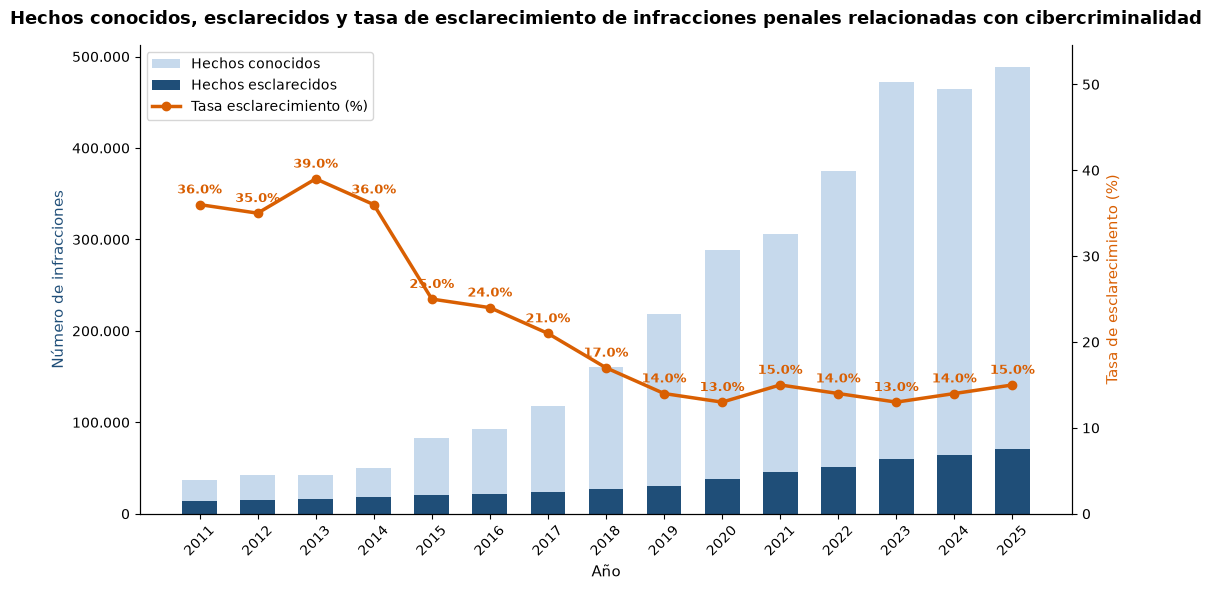

In [13]:
fig, ax1 = plt.subplots(figsize=(11, 6))

# Barras: Hechos conocidos vs esclarecidos
x = nacional_esc.index.astype(str)
ax1.bar(x, nacional_esc["Hechos_Conocidos"], color="#c6d9ec", label="Hechos conocidos", width=0.6)
ax1.bar(x, nacional_esc["Hechos_Esclarecidos"], color="#1f4e78", label="Hechos esclarecidos", width=0.6)

ax1.set_xlabel("Año", fontsize=11)
ax1.set_ylabel("Número de infracciones", fontsize=11, color="#1f4e78")
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, pos: f"{int(val):,}".replace(",", ".")))
ax1.tick_params(axis="x", rotation=45)

# Segundo eje Y: Línea con la Tasa de Esclarecimiento (%)
ax2 = ax1.twinx()
ax2.plot(x, nacional_esc["Tasa_Esclarecimiento_%"], color="#d95f02", marker="o", linewidth=2.5, label="Tasa esclarecimiento (%)")
ax2.set_ylabel("Tasa de esclarecimiento (%)", fontsize=11, color="#d95f02")
ax2.set_ylim(0, max(nacional_esc["Tasa_Esclarecimiento_%"]) * 1.4)

# Etiquetas de porcentaje sobre los puntos de la línea
for i, txt in enumerate(nacional_esc["Tasa_Esclarecimiento_%"]):
    ax2.annotate(f"{txt:.1f}%", (x[i], nacional_esc["Tasa_Esclarecimiento_%"].iloc[i]),
                 textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, fontweight="bold", color="#d95f02")

ax1.set_title("Hechos conocidos, esclarecidos y tasa de esclarecimiento de infracciones penales relacionadas con cibercriminalidad", fontsize=13, fontweight="bold", pad=15)
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

# Unificar leyendas de ambos ejes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.show()


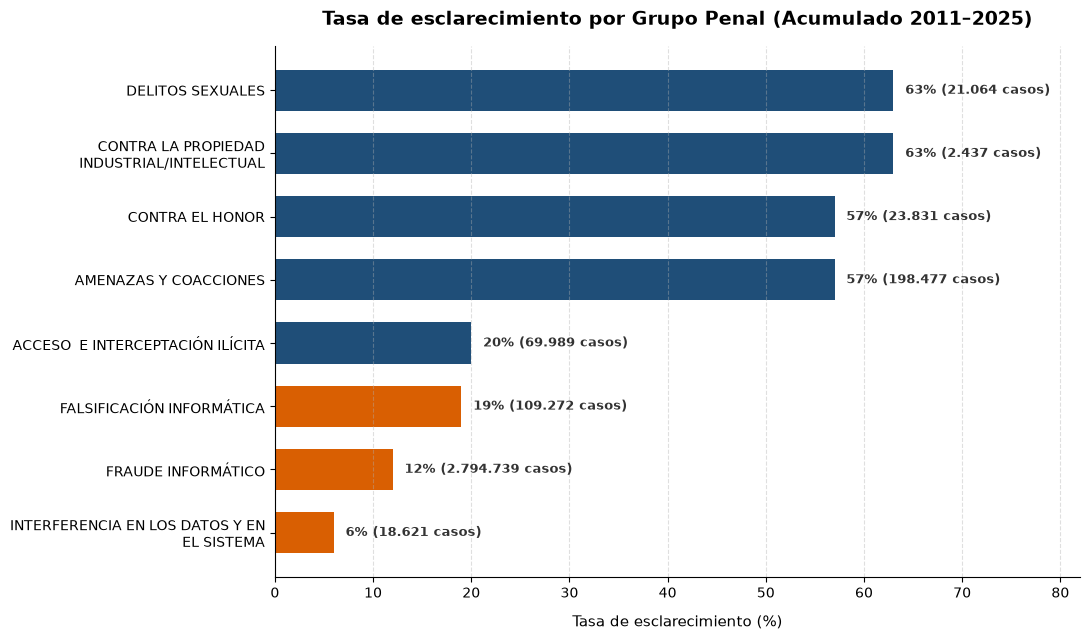

In [25]:
import matplotlib.pyplot as plt
import textwrap

# Ordenar de menor a mayor para que la barra más alta quede arriba en el gráfico horizontal
grupo_plot = grupo_esc.sort_values(by="Tasa_Esclarecimiento_%", ascending=True)

# Ajustar nombres largos en dos líneas para mayor legibilidad
etiquetas_grupo = [textwrap.fill(str(nombre), width=32) for nombre in grupo_plot.index]

# Colores: destacar en naranja los delitos con tasa crítica (<20%) y en azul los de alta resolución
colores = ["#d95f02" if tasa < 20 else "#1f4e78" for tasa in grupo_plot["Tasa_Esclarecimiento_%"]]

fig, ax = plt.subplots(figsize=(11, 6.5))
bars = ax.barh(etiquetas_grupo, grupo_plot["Tasa_Esclarecimiento_%"], color=colores, height=0.65)

ax.set_title("Tasa de esclarecimiento por Grupo Penal (Acumulado 2011–2025)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Tasa de esclarecimiento (%)", fontsize=11, labelpad=10)

# Limpiar bordes superiores y derechos
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.4)

# Añadir el porcentaje y el volumen total de hechos conocidos al final de cada barra
for bar, (idx, row) in zip(bars, grupo_plot.iterrows()):
    tasa = row["Tasa_Esclarecimiento_%"]
    conocidos = f"{int(row['Hechos_Conocidos']):,}".replace(",", ".")
    ax.text(
        bar.get_width() + 1.2,
        bar.get_y() + bar.get_height() / 2,
        f"{tasa:.0f}% ({conocidos} casos)",
        va="center",
        ha="left",
        fontsize=9.5,
        fontweight="bold",
        color="#333333"
    )

ax.set_xlim(0, 82)
plt.tight_layout()
plt.show()


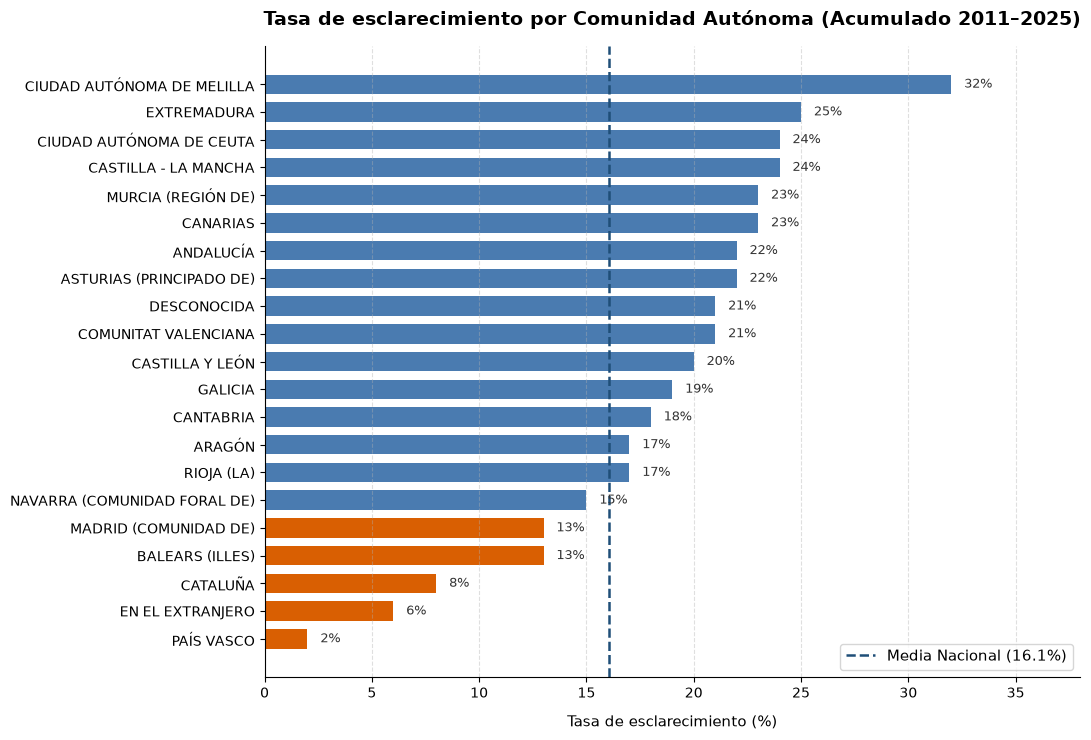

In [26]:
# Filtrar solo territorios nacionales (excluyendo Total Nacional, Extranjero y Desconocida)
# excluir_territorio = ["TOTAL NACIONAL", "EN EL EXTRANJERO", "DESCONOCIDA"]
excluir_territorio = ["TOTAL NACIONAL"]

ccaa_territorio = df_dataset4[~df_dataset4["Comunidades autónomas"].isin(excluir_territorio)].groupby("Comunidades autónomas")[["Hechos_Conocidos", "Hechos_Esclarecidos"]].sum()
ccaa_territorio["Tasa_Esclarecimiento_%"] = (ccaa_territorio["Hechos_Esclarecidos"] / ccaa_territorio["Hechos_Conocidos"] * 100).round()

# Calcular la media nacional para dibujar una línea de referencia
total_nac = df_dataset4[df_dataset4["Comunidades autónomas"] == "TOTAL NACIONAL"]
media_nacional = (total_nac["Hechos_Esclarecidos"].sum() / total_nac["Hechos_Conocidos"].sum()) * 100

ccaa_plot = ccaa_territorio.sort_values(by="Tasa_Esclarecimiento_%", ascending=True)

fig, ax = plt.subplots(figsize=(11, 7.5))

# Destacar en naranja las comunidades con menor tasa y en azul el resto
colores_ccaa = ["#d95f02" if tasa < 14 else "#4a7bb0" for tasa in ccaa_plot["Tasa_Esclarecimiento_%"]]
bars = ax.barh(ccaa_plot.index, ccaa_plot["Tasa_Esclarecimiento_%"], color=colores_ccaa, height=0.7)

# Línea vertical con la media nacional
ax.axvline(media_nacional, color="#1f4e78", linestyle="--", linewidth=1.8, label=f"Media Nacional ({media_nacional:.1f}%)")

ax.set_title("Tasa de esclarecimiento por Comunidad Autónoma (Acumulado 2011–2025)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Tasa de esclarecimiento (%)", fontsize=11, labelpad=10)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.4)

for bar in bars:
    valor = bar.get_width()
    ax.text(
        valor + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{valor:.0f}%",
        va="center",
        ha="left",
        fontsize=9.5,
        color="#333333"
    )

ax.set_xlim(0, 38)
ax.legend(loc="lower right", fontsize=10.5)
plt.tight_layout()
plt.show()
